# Nairobi Rentals — Statistics 


## 0. Getting started

In [2]:
import pandas as pd, numpy as np
from scipy import stats as st
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.oneway import anova_oneway

pd.options.display.float_format = '{:,.2f}'.format
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True, 'grid.alpha': .3})

df = pd.read_csv("C:/Users/hp/Desktop/tembo_project/Nairobi prediction analysis/Data/nairobi_rentals_reemio.csv", parse_dates=["listing_date"])

rent = df["rent_kes_2026"]

def save(name):
    plt.tight_layout(); plt.savefig(f"../images/{name}.png", dpi=130); plt.show()

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1486 entries, 0 to 1485
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   listing_id              1486 non-null   str           
 1   listing_date            1486 non-null   datetime64[us]
 2   listing_weekday         1486 non-null   str           
 3   neighbourhood           1486 non-null   str           
 4   sub_county              1486 non-null   str           
 5   county                  1486 non-null   str           
 6   market_segment          1486 non-null   str           
 7   property_category       1486 non-null   str           
 8   unit_type               1486 non-null   str           
 9   bedrooms                1486 non-null   int64         
 10  bathrooms               1486 non-null   int64         
 11  balconies               1486 non-null   int64         
 12  floor_level             1486 non-null   int64         
 13 

In [3]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
listing_date,1486,2026-03-24 20:49:05.895020,2025-12-16 00:00:00,2026-01-06 00:00:00,2026-02-19 00:00:00,2026-06-02 18:00:00,2026-09-18 00:00:00,NaN
bedrooms,"1,486.00",1.63,0.00,1.00,2.00,2.00,6.00,0.80
bathrooms,"1,486.00",1.41,1.00,1.00,1.00,2.00,6.00,0.62
balconies,"1,486.00",0.86,0.00,1.00,1.00,1.00,4.00,0.55
floor_level,"1,486.00",2.79,0.00,1.00,2.00,3.00,29.00,2.46
rent_kes_2026,"1,486.00","33,753.03","6,000.00","18,000.00","25,000.00","37,000.00","510,000.00","31,487.78"
deposit_kes,"1,486.00","40,237.97",0.00,"18,000.00","25,000.00","38,000.00","510,000.00","47,650.85"
distance_to_cbd_km,"1,486.00",20.94,1.80,12.60,17.80,27.20,55.30,12.03
size_sqm,"1,486.00",65.36,15.00,45.00,65.00,79.00,254.00,27.44
building_age_years,"1,486.00",6.81,0.00,3.00,6.00,9.00,35.00,4.84


**Classifying the columns** (the type decides which summary and test are allowed):

| Type | Columns |
|---|---|
| Nominal (labels, no order) | `neighbourhood`, `sub_county`, `county`, `property_category`, `listing_weekday`, `furnished`, `parking`, `gym`, `borehole`, `listed_by` (and the IDs `listing_id`, `building_id`) |
| Ordinal (ordered labels) | `market_segment` (roughly Affordable < Mid-Range < Luxury), `unit_type` (Studio < 1 Bedroom < ... < 6 Bedroom) |
| Discrete (counts) | `bedrooms`, `bathrooms`, `balconies`, `floor_level`, `building_age_years`, `days_on_market` |
| Continuous (measured) | `rent_kes_2026`, `rent_kes_2025`, `deposit_kes`, `distance_to_cbd_km`, `size_sqm`, `peak_commute_min`, `building_occupancy_pct`, `tenant_satisfaction_10` |
| Date | `listing_date` |

`tenant_satisfaction_10` is a score out of 10 and could arguably be ordinal. I treat it as continuous but use rank-based tests for it later because it is skewed and capped at 10.

# Part A — Measures of central tendency


### A1. Mean, median and mode of rent

In [4]:
print("Mean  :", round(rent.mean(), 1))
print("Median:", rent.median())
print("Mode  :", rent.mode().tolist())

Mean  : 33753.0
Median: 25000.0
Mode  : [20000]


**Interpretation.** Mean (about KES 33,753) > median (25,000) > mode (20,000). When the mean is the largest, the distribution is **right-skewed**: most listings are modestly priced and a small number of very expensive units drag the mean upwards.

### A2. 'What does a typical house cost to rent?'

I  quote the **median (KES 25,000)**, possibly with the mode (KES 20,000) as 'the most common asking rent'. The mean is inflated by luxury units and describes almost nobody's actual rent.

### A3. Mean by hand, and how many listings are below it?

In [5]:
manual_mean = rent.sum() / len(df)
print(manual_mean, rent.mean(), np.isclose(manual_mean, rent.mean()))
below = (rent < rent.mean()).sum()
print(f"{below} listings ({below/len(df):.1%}) rent for less than the mean")

33753.02826379542 33753.02826379542 True
1020 listings (68.6%) rent for less than the mean


**Interpretation.** About **69%** of listings are cheaper than the mean, far more than half. That only happens in a right-skewed distribution: a few very high rents lift the mean above the typical listing.

### A4. Mean vs median rent by number of bedrooms

In [6]:
g = df.groupby("bedrooms")["rent_kes_2026"].agg(n="count", mean="mean", median="median")
g["gap_%"] = (g["mean"] - g["median"]) / g["median"] * 100
g

,n,mean,median,gap_%
bedrooms,,,,
0,93,"18,606.45","15,000.00",24.04
1,546,"22,837.18","18,000.00",26.87
2,697,"35,567.43","30,000.00",18.56
3,132,"72,401.52","65,000.00",11.39
4,13,"75,384.62","75,000.00",0.51
5,3,"120,000.00","120,000.00",0.00
6,2,"135,000.00","135,000.00",0.00


**Interpretation.** The percentage gap is widest for **1-bedroom units (about 27%)**, followed by studios (bedrooms = 0, about 24%) and 2-bedrooms (about 19%). The gaps for 4, 5 and 6 bedrooms are near zero, but those groups hold only 13, 3 and 2 listings, so they are not reliable.

### A5. Modes of `bedrooms`, `market_segment`, `neighbourhood`

In [6]:
for c in ["bedrooms", "market_segment", "neighbourhood"]:
    print(c, "->", df[c].mode().tolist())

bedrooms -> [2]
market_segment -> ['Family Friendly']
neighbourhood -> ['Utawala']


**Interpretation.** Most common: 2 bedrooms, *Family Friendly*, and *Utawala*. A mean of `market_segment` or `neighbourhood` is meaningless because they are labels, not numbers: you cannot add 'Utawala' to 'Ruaka' and divide by two. 

### A6. Remove the five most expensive listings

In [7]:
trimmed = rent.sort_values().iloc[:-5]
pd.DataFrame({"mean": [rent.mean(), trimmed.mean()], "median": [rent.median(), trimmed.median()]},
             index=["all 1,486", "without top 5"])

,mean,median
"all 1,486","33,753.03","25,000.00"
without top 5,"32,607.02","25,000.00"


**Interpretation.** The mean drops by about KES 1,150 (33,753 to about 32,607); the median does not move (25,000). This shows the median is **resistant to outliers**: it only depends on the middle of the ordered data.

### A7. Mean vs median for occupancy and commute: predict, then plot

        building_occupancy_pct  peak_commute_min
mean                     87.71             50.05
median                   89.90             50.00


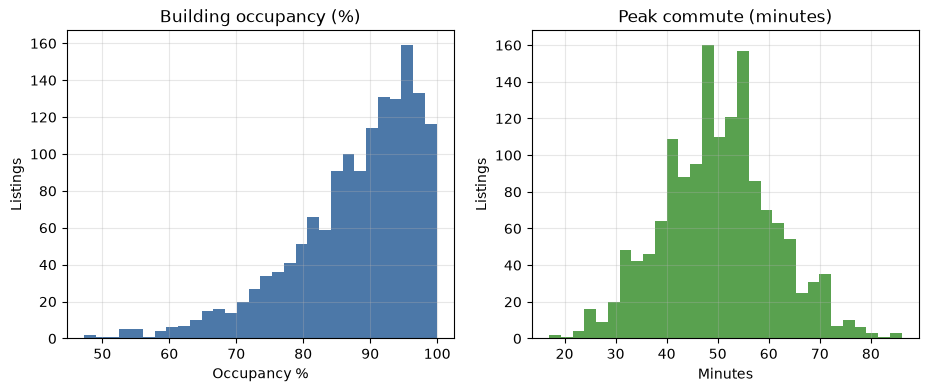

In [9]:
print(df[["building_occupancy_pct", "peak_commute_min"]].agg(["mean", "median"]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["building_occupancy_pct"].plot.hist(bins=30, ax=ax[0], color="#4c78a8"); ax[0].set(title="Building occupancy (%)", xlabel="Occupancy %", ylabel="Listings")
df["peak_commute_min"].plot.hist(bins=30, ax=ax[1], color="#59a14f"); ax[1].set(title="Peak commute (minutes)", xlabel="Minutes", ylabel="Listings")
plt.savefig("A7_occupancy_commute_hist")
plt.show()

**Interpretation.** Occupancy: mean (87.7) < median (89.9), so my prediction is **left-skewed** (a long tail of low occupancy); the histogram confirms it. Commute: mean (50.05) is about the same as the median (50), so **symmetric** and bell-shaped.

### A8. Mean of county means vs overall mean (weighted mean)

In [11]:
cm = df.groupby("county")["rent_kes_2026"].agg(["count", "mean"])
print(cm)
print("Average of the 4 county means  :", round(cm["mean"].mean(), 1))
print("Weighted by listings per county:", round((cm["mean"] * cm["count"]).sum() / cm["count"].sum(), 1))
print("Overall mean                   :", round(rent.mean(), 1))

          count      mean
county                   
Kajiado      64 25,153.12
Kiambu      743 27,487.21
Machakos     51 44,519.61
Nairobi     628 41,168.31
Average of the 4 county means  : 34582.1
Weighted by listings per county: 33753.0
Overall mean                   : 33753.0


**Interpretation.** The simple average of the four county means (about 34,582) treats tiny Machakos (51 listings) the same as Kiambu (743). The overall mean (33,753) is a **weighted mean**: each county counts in proportion to its number of listings. Once weighted, the two agree exactly.

# Part B — Measures of dispersion
**Idea in plain English:** two datasets can share a mean and look completely different. Range, IQR, variance, standard deviation (SD) and the coefficient of variation (CV = SD ÷ mean) each describe how spread out the values are. Only the IQR ignores the extremes.

### B1. Range, IQR, variance, SD of rent

In [12]:
q1, q3 = rent.quantile([.25, .75])
print("Range :", rent.min(), "to", rent.max(), "(width", rent.max()-rent.min(), ")")
print("Q1, Q3, IQR:", q1, q3, q3-q1)
print("Variance:", f"{rent.var():,.0f}")
print("SD      :", round(rent.std(), 1))

Range : 6000 to 510000 (width 504000 )
Q1, Q3, IQR: 18000.0 37000.0 19000.0
Variance: 991,480,230
SD      : 31487.8


**Interpretation.** Rents run from KES 6,000 to 510,000. The middle half sits between 18,000 and 37,000 (IQR = 19,000). The SD is about KES 31,488. The **variance (about 991 million) is awkward** because it is measured in *KES squared*, and 'square shillings' mean nothing to a tenant. The SD takes the square root and returns to KES.

### B2. CV of rent by county

In [13]:
cv = df.groupby("county")["rent_kes_2026"].agg(mean="mean", sd="std")
cv["CV"] = cv["sd"] / cv["mean"]
cv.sort_values("CV", ascending=False)

,mean,sd,CV
county,,,
Nairobi,"41,168.31","43,000.58",1.04
Kiambu,"27,487.21","16,184.62",0.59
Machakos,"44,519.61","26,100.38",0.59
Kajiado,"25,153.12","12,739.17",0.51


**Interpretation.** **Nairobi** has the highest CV (about 1.04: its SD is larger than its mean); the other counties are around 0.5 to 0.6. The CV is fairer than comparing SDs because it expresses spread *relative to the average*: a KES 13,000 SD means something very different when the average is 25,000 (Kajiado) than when it is 41,000 (Nairobi).

### B3. The 1.5 × IQR rule: upper fence

In [14]:
fence = q3 + 1.5 * (q3 - q1)
out = df[rent > fence]
print("Upper fence:", fence, "| listings above:", len(out))
print(out["market_segment"].value_counts())
print(out["rent_kes_2026"].describe())
print(out.sort_values("rent_kes_2026", ascending=False)[["neighbourhood","market_segment","unit_type","rent_kes_2026"]].head(8))

Upper fence: 65500.0 | listings above: 119
market_segment
Family Friendly    78
Mid-Range          23
Luxury             14
Affordable          4
Name: count, dtype: int64
count       119.00
mean    109,974.79
std      64,745.32
min      70,000.00
25%      75,000.00
50%      90,000.00
75%     120,000.00
max     510,000.00
Name: rent_kes_2026, dtype: float64
    neighbourhood   market_segment  unit_type  rent_kes_2026
629     Westlands           Luxury  3 Bedroom         510000
630     Westlands           Luxury  3 Bedroom         384000
627     Westlands           Luxury  2 Bedroom         324000
626     Westlands           Luxury  2 Bedroom         324000
633     Westlands           Luxury  2 Bedroom         324000
628     Westlands           Luxury  1 Bedroom         241000
153      Kilimani  Family Friendly  3 Bedroom         200000
620     Westlands           Luxury  2 Bedroom         160000


**Interpretation.** The upper fence is KES 65,500 and **119 listings** (8%) lie above it. By segment they are Family Friendly (78), Mid-Range (23), Luxury (14) and Affordable (4); the very top are Westlands Luxury units (up to KES 510,000). These look like genuine expensive homes, not typing errors. They should **not be deleted**: they are real, part of the market, and removing them would misrepresent it. If they distort an analysis, use methods that cope with them (median, log scale, rank-based tests).

### B4. Boxplot of rent by bedrooms: normal and log scale

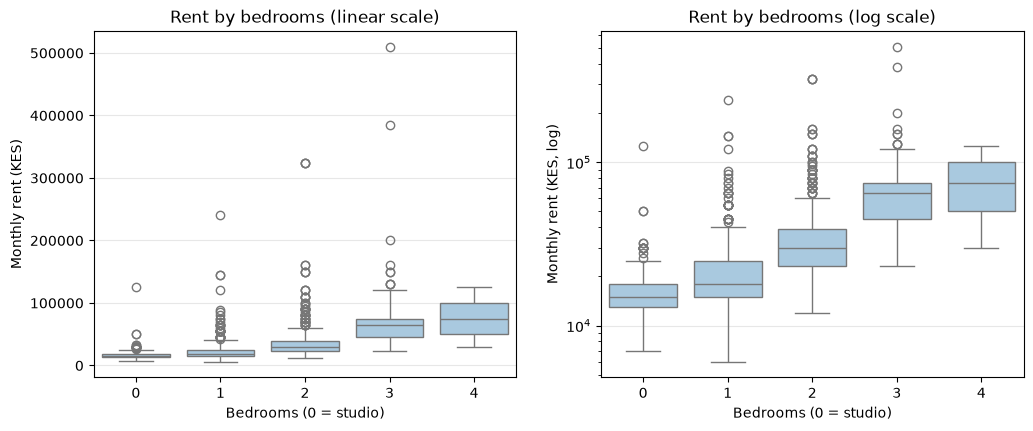

In [16]:
sub = df[df.bedrooms <= 4]   # 5 and 6 bedrooms have only 5 listings in total
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=sub, x="bedrooms", y="rent_kes_2026", ax=ax[0], color="#a0cbe8"); ax[0].set(title="Rent by bedrooms (linear scale)", xlabel="Bedrooms (0 = studio)", ylabel="Monthly rent (KES)")
sns.boxplot(data=sub, x="bedrooms", y="rent_kes_2026", ax=ax[1], color="#a0cbe8"); ax[1].set_yscale("log"); ax[1].set(title="Rent by bedrooms (log scale)", xlabel="Bedrooms (0 = studio)", ylabel="Monthly rent (KES, log)")
plt.savefig("B4_rent_by_bedrooms_boxplot")
plt.show()

**Interpretation.** On the linear scale the expensive outliers squash all the boxes into the bottom of the chart, so studios, 1-beds and 2-beds look almost the same. The log scale gives equal visual room to *percentage* differences, so the real step-ups between bedroom classes and the spread *within* the cheaper classes become visible.

### B5. Five-number summary of `days_on_market`

In [17]:
d_m = df["days_on_market"]
five = d_m.quantile([0, .25, .5, .75, 1]); five.index = ["min", "Q1", "median", "Q3", "max"]
print(five)
print("Max - Q3:", d_m.max() - d_m.quantile(.75), "| Q1 - min:", d_m.quantile(.25) - d_m.min())

min        1.00
Q1         8.00
median    19.00
Q3        39.00
max      338.00
Name: days_on_market, dtype: float64
Max - Q3: 299.0 | Q1 - min: 7.0


**Interpretation.** The maximum (338 days) is about 299 days above Q3 (39), while the minimum (1) is only 7 days below Q1 (8). The upper tail is far longer than the lower one, so the data are **right-skewed**: most units are let within weeks, a few sit on the market for most of a year.

### B6. Skewness of five columns

In [15]:
sk = df[["rent_kes_2026","days_on_market","building_occupancy_pct","tenant_satisfaction_10","peak_commute_min"]].skew().sort_values()
sk

building_occupancy_pct   -1.16
tenant_satisfaction_10   -0.73
peak_commute_min          0.08
days_on_market            2.97
rent_kes_2026             6.04
dtype: float64

**Interpretation.**
- **Right-skewed (positive):** rent (about 6.0), days on market (about 3.0)
- **Left-skewed (negative):** building occupancy (about −1.2), tenant satisfaction (about −0.7)
- **Roughly symmetric:** peak commute (about 0.1)

### B7. Z-scores of rent vs the IQR rule

In [19]:
z = (rent - rent.mean()) / rent.std()
print("|z| > 3:", (z.abs() > 3).sum(), "| above IQR fence:", (rent > fence).sum())

|z| > 3: 22 | above IQR fence: 119


**Interpretation.** Only **22** listings have |z| > 3, compared with **119** above the IQR fence. They disagree because the z-score uses the mean and SD, and those are themselves inflated by the very outliers we are hunting (the SD is huge, so a rent has to be very far out to look 'unusual'). The IQR rule uses quartiles, which the outliers cannot move, so it flags more. For skewed data the IQR rule is the more honest one.

### B8. SD of `size_sqm`: all units vs 2-bedroom units

In [17]:
print("All units:", round(df.size_sqm.std(), 2), "| 2-bedroom only:", round(df[df.bedrooms==2].size_sqm.std(), 2))

All units: 27.44 | 2-bedroom only: 8.76


**Interpretation.** The SD falls from about 27.4 to about 8.8 sqm. Overall, size varies mainly because studios and 4-bedroom homes are very different sizes; within one bedroom class, units are far more alike. Most of the overall spread is *between-group* difference, not variation within a group.

# Part C — Distributions and normality
**Idea in plain English:** many tests (t-test, ANOVA) work best when the data (or the average of the data) follow the bell curve. We check with (1) a histogram, (2) a Q–Q plot (points on the line means normal), and (3) a formal test like Shapiro–Wilk, in that order of importance.

### C1. Histograms side by side

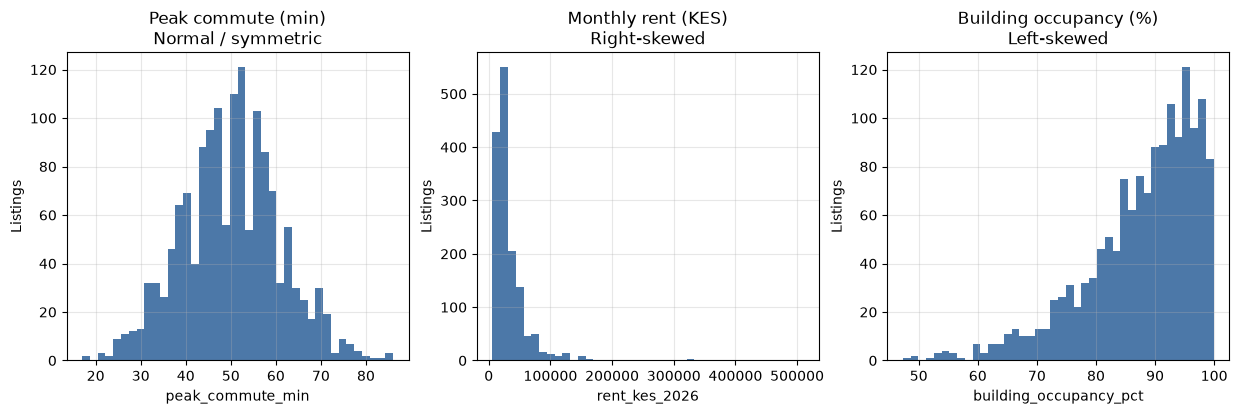

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (c, t) in zip(ax, [("peak_commute_min", "Peak commute (min)\nNormal / symmetric"),
                         ("rent_kes_2026", "Monthly rent (KES)\nRight-skewed"),
                         ("building_occupancy_pct", "Building occupancy (%)\nLeft-skewed")]):
    df[c].plot.hist(bins=40, ax=a, color="#4c78a8"); a.set(title=t, xlabel=c, ylabel="Listings")
plt.savefig("C1_histograms")
plt.show()

**Interpretation.** Commute: normal. Rent: right-skewed (long tail to the right). Occupancy: left-skewed (long tail to the left, piled up near 100%).

### C2. The empirical rule (68–95–99.7)

In [21]:
for c in ["peak_commute_min", "rent_kes_2026"]:
    x = df[c]; print(c, [f"{((x-x.mean()).abs() <= k*x.std()).mean():.1%}" for k in (1, 2, 3)])

peak_commute_min ['67.0%', '95.1%', '99.7%']
rent_kes_2026 ['92.0%', '96.4%', '98.5%']


**Interpretation.** Commute: about 67%, 95%, 99.7%, almost exactly the rule, as expected for a normal distribution. Rent: about 92%, 96%, 99%: too many values within 1 SD (the bulk is crowded at the low end) and a heavier tail than a bell curve. The rule only works for normal data.

### C3. Shapiro–Wilk on a random sample of 500

In [22]:
for c in ["peak_commute_min", "rent_kes_2026"]:
    s = df[c].sample(500, random_state=42)
    print(c, st.shapiro(s))

peak_commute_min ShapiroResult(statistic=np.float64(0.9945434173796599), pvalue=np.float64(0.07215049246004679))
rent_kes_2026 ShapiroResult(statistic=np.float64(0.6563689283118918), pvalue=np.float64(1.6906876561943194e-30))


**Hypotheses:** H₀: the data come from a normal distribution; H₁: they do not.

**Interpretation.** Commute: p is above 0.05, so there is no evidence against normality (the exact p-value changes with the random sample). Rent: p is essentially zero, so it is clearly not normal.

**Why sample?** With very large samples Shapiro–Wilk becomes over-sensitive: it detects tiny, practically irrelevant departures from normality and rejects almost everything (scipy also warns that its p-values are unreliable for n above 5,000). A sample of 500 keeps the test in a sensible range.

### C4. Log of rent

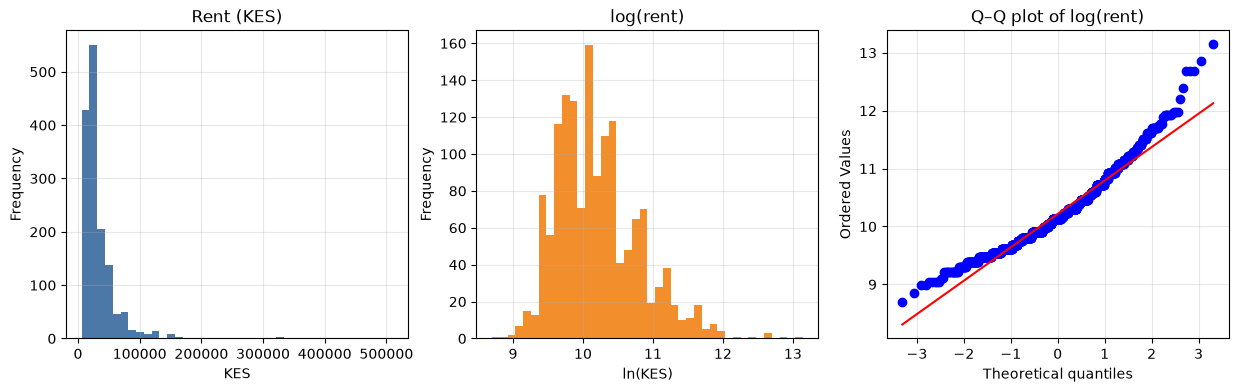

skew raw: 6.04 | skew log: 0.87
Shapiro (n=500): ShapiroResult(statistic=np.float64(0.9614149085499092), pvalue=np.float64(3.592039285351682e-10))
Shapiro (all 1,486): ShapiroResult(statistic=np.float64(0.9580286660912367), pvalue=np.float64(2.8654026772656096e-20))


In [24]:
lr = np.log(rent)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
rent.plot.hist(bins=40, ax=ax[0], color="#4c78a8"); ax[0].set(title="Rent (KES)", xlabel="KES")
lr.plot.hist(bins=40, ax=ax[1], color="#f28e2b"); ax[1].set(title="log(rent)", xlabel="ln(KES)")
st.probplot(lr, plot=ax[2]); ax[2].set_title("Q–Q plot of log(rent)")
plt.savefig("C4_log_rent")
plt.show()
print("skew raw:", round(rent.skew(), 2), "| skew log:", round(lr.skew(), 2))
print("Shapiro (n=500):", st.shapiro(lr.sample(500, random_state=42)))
print("Shapiro (all 1,486):", st.shapiro(lr))

**Interpretation.** Skewness drops from about 6.0 to about 0.9: log-rent is **much closer to bell-shaped**, and the Q–Q plot hugs the line in the middle. Shapiro–Wilk still rejects (p < 0.001) because of the leftover right tail and because the test is very sensitive on large samples. **Lesson:** trust the plots and ask *how bad* the departure is; do not treat a tiny p-value from a normality test on a big sample as a disaster.

### C5. Mixing normal groups gives a non-normal whole

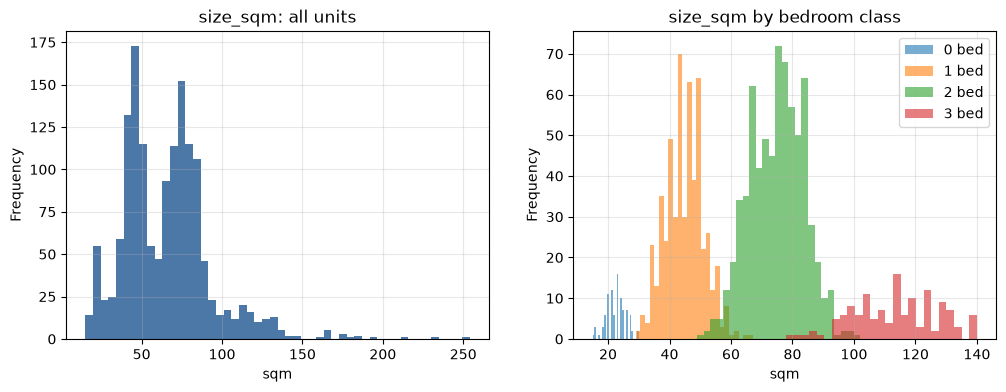

Shapiro 2-bedroom: ShapiroResult(statistic=np.float64(0.9952683577722486), pvalue=np.float64(0.030994876665191053))


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["size_sqm"].plot.hist(bins=50, ax=ax[0], color="#4c78a8"); ax[0].set(title="size_sqm: all units", xlabel="sqm")
for b in [0, 1, 2, 3]:
    df[df.bedrooms == b]["size_sqm"].plot.hist(bins=25, alpha=.6, ax=ax[1], label=f"{b} bed")
ax[1].set(title="size_sqm by bedroom class", xlabel="sqm"); ax[1].legend()
plt.savefig("C5_size_mixture")
plt.show()
print("Shapiro 2-bedroom:", st.shapiro(df[df.bedrooms==2].size_sqm))

**Explanation.** Each bedroom class has its own bell curve centred at a different size (small for studios, larger with each extra bedroom). Stack them in one histogram and you get overlapping bumps, with many units in the smaller classes and a long tail from big homes: the *whole* is skewed even though each *part* is normal. (Shapiro–Wilk on the 2-bedroom group gives p of about 0.03: a very slight departure that only shows up because the group has almost 700 units; the histogram is clearly bell-shaped.) 

### C6. Central Limit Theorem demonstration

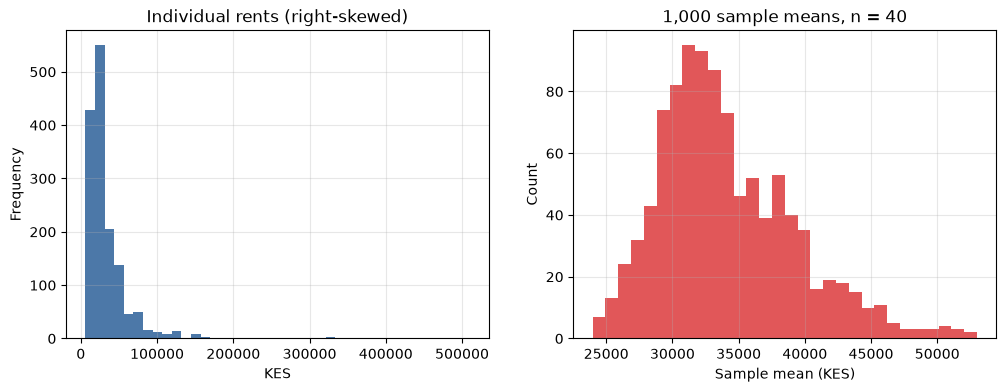

Mean of means: 34091 | SD of means: 5115 | skew: 0.84


In [26]:
rng = np.random.default_rng(1)
means = [rent.sample(40, random_state=int(s)).mean() for s in rng.integers(0, 10**6, 1000)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rent.plot.hist(bins=40, ax=ax[0], color="#4c78a8"); ax[0].set(title="Individual rents (right-skewed)", xlabel="KES")
ax[1].hist(means, bins=30, color="#e15759"); ax[1].set(title="1,000 sample means, n = 40", xlabel="Sample mean (KES)", ylabel="Count")
plt.savefig("C6_clt")
plt.show()
print("Mean of means:", round(np.mean(means)), "| SD of means:", round(np.std(means)), "| skew:", round(st.skew(means), 2))

**Interpretation.** The raw rents are heavily skewed, but the 1,000 sample means are far more bell-shaped, centred near the true mean (about 33,800), with a much smaller spread (about 5,100, close to 31,488 ÷ √40). That is the **Central Limit Theorem**: averages of reasonably large samples are approximately normal even if the underlying data are not. It is why a t-test about a *mean* is still reasonable on skewed rent data when n is large. The sample means are still slightly right-skewed at n = 40 because rents are so extreme; with n = 1,486 we are well beyond that.

### C7. 95% confidence interval for mean rent

In [27]:
ci = st.t.interval(0.95, df=len(rent)-1, loc=rent.mean(), scale=st.sem(rent))
print("95% CI for mean rent:", [round(x) for x in ci])

95% CI for mean rent: [32151, 35355]


**Interpretation.** 95% CI is about **KES 32,151 to 35,355**. In one sentence: if we repeated this sampling many times, about 95% of intervals built this way would contain the true average asking rent of listings like these.

# Part D — Parametric hypothesis tests


In [28]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*np.var(a, ddof=1) + (nb-1)*np.var(b, ddof=1)) / (na+nb-2))
    return (np.mean(a) - np.mean(b)) / sp

## One-sample t-tests

### D1. Utawala 1-bedroom: is the average KES 18,000?


n = 51 | mean = 18882 | median = 20000.0
Shapiro: ShapiroResult(statistic=np.float64(0.9494194021424036), pvalue=np.float64(0.029810304072191162))
TtestResult(statistic=np.float64(1.3884723144543343), pvalue=np.float64(0.17114826630667673), df=np.int64(50))


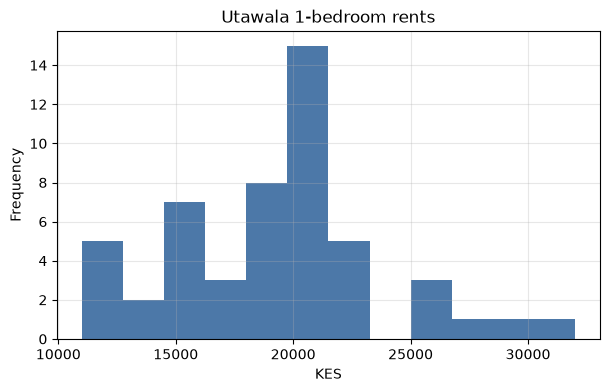

In [30]:
u = df[(df.neighbourhood == "Utawala") & (df.bedrooms == 1)]["rent_kes_2026"]
print("n =", len(u), "| mean =", round(u.mean()), "| median =", u.median())
print("Shapiro:", st.shapiro(u))
print(st.ttest_1samp(u, 18000))
u.plot.hist(bins=12, color="#4c78a8"); plt.title("Utawala 1-bedroom rents"); plt.xlabel("KES"); plt.savefig("D1_utawala_hist");plt.show()

**Conclusion.** t(50) is about 1.39 and p is about 0.17, above 0.05, so we **fail to reject H₀**. The sample average (about KES 18,882) is not far enough from 18,000 to say the agent is wrong. That is not proof the agent is right, just no evidence against the claim. Shapiro–Wilk (p about 0.03) shows mild non-normality, which is why E1 repeats this with a rank test.

### D2. County planner: is average peak commute 50 minutes?


In [31]:
print(df.peak_commute_min.mean()); print(st.ttest_1samp(df.peak_commute_min, 50))

50.05383580080753
TtestResult(statistic=np.float64(0.19075102058875987), pvalue=np.float64(0.8487467376105307), df=np.int64(1485))


**Conclusion.** Mean about 50.05 min, t about 0.19, p about 0.85: **fail to reject**. The data are consistent with the planner's claim of 50 minutes.

### D3. Ruaka 2-bedroom: is the average KES 30,000?


n = 29 | mean = 40172 | median = 43000.0
Shapiro: ShapiroResult(statistic=np.float64(0.9363224536162326), pvalue=np.float64(0.08034328734760698))
TtestResult(statistic=np.float64(3.5529645655615805), pvalue=np.float64(0.0013732364439991915), df=np.int64(28))


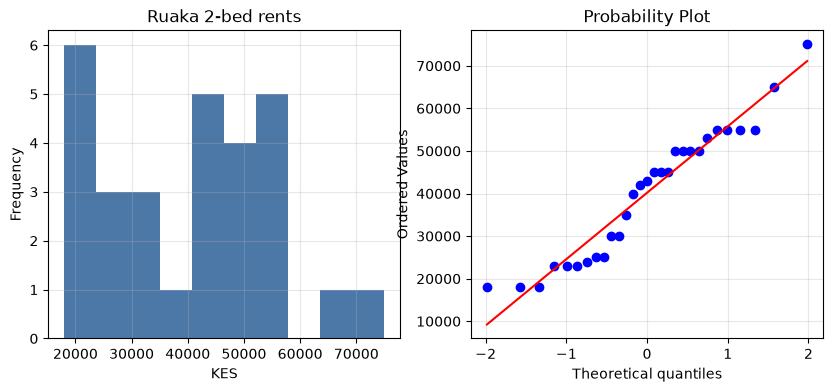

In [32]:
ru = df[(df.neighbourhood == "Ruaka") & (df.bedrooms == 2)]["rent_kes_2026"]
print("n =", len(ru), "| mean =", round(ru.mean()), "| median =", ru.median())
print("Shapiro:", st.shapiro(ru))
print(st.ttest_1samp(ru, 30000))
fig, ax = plt.subplots(1, 2, figsize=(10, 4)); ru.plot.hist(bins=10, ax=ax[0], color="#4c78a8"); ax[0].set(title="Ruaka 2-bed rents", xlabel="KES"); st.probplot(ru, plot=ax[1]); plt.savefig("D3_ruaka"); plt.show()

**Conclusion.** t(28) is about 3.55, p about 0.001: **reject H₀**. The average Ruaka 2-bedroom (about KES 40,172) is significantly higher than 30,000. Shapiro–Wilk (p about 0.08) and the Q–Q plot show no strong evidence against normality, so the t-test is reasonable; the Wilcoxon test agrees (p about 0.002).

## Independent two-sample t-tests

### D4. 2-bedroom units: does parking raise rent?


In [33]:
b2 = df[df.bedrooms == 2]
pk = b2[b2.parking == "Yes"]["rent_kes_2026"]; npk = b2[b2.parking == "No"]["rent_kes_2026"]
print("n:", len(pk), len(npk), "| means:", round(pk.mean()), round(npk.mean()), "| medians:", pk.median(), npk.median())
print("Levene:", st.levene(pk, npk))
print("Student:", st.ttest_ind(pk, npk))
print("Welch  :", st.ttest_ind(pk, npk, equal_var=False))
print("Cohen's d:", round(cohens_d(pk, npk), 2))

n: 445 252 | means: 41418 25237 | medians: 35000.0 24000.0
Levene: LeveneResult(statistic=np.float64(26.406178171340525), pvalue=np.float64(3.598844781516755e-07))
Student: TtestResult(statistic=np.float64(7.794043779036175), pvalue=np.float64(2.3727089099808863e-14), df=np.float64(695.0))
Welch  : TtestResult(statistic=np.float64(9.932688859054014), pvalue=np.float64(1.6591445070177638e-21), df=np.float64(554.1129607299387))
Cohen's d: 0.61


**Conclusion.** Levene p < 0.001, so the variances are unequal and we use **Welch's t-test**: t about 9.9, p < 0.001, so **reject H₀**. 2-bedroom units with parking rent for about **KES 16,000 more per month** on average (about 41,400 vs 25,200), a large effect (d about 0.8).

### D5. Furnished vs unfurnished (all units)


In [30]:
f = df[df.furnished == "Yes"]["rent_kes_2026"]; nf = df[df.furnished == "No"]["rent_kes_2026"]
print("n:", len(f), len(nf), "| means:", round(f.mean()), round(nf.mean()), "| medians:", f.median(), nf.median())
print("Levene:", st.levene(f, nf)); print("Welch:", st.ttest_ind(f, nf, equal_var=False)); print("d:", round(cohens_d(f, nf), 2))

n: 152 1334 | means: 74822 29073 | medians: 55000.0 24000.0
Levene: LeveneResult(statistic=np.float64(158.19976209903623), pvalue=np.float64(1.5115904008644417e-34))
Welch: TtestResult(statistic=np.float64(8.184280248727383), pvalue=np.float64(9.750365382438012e-14), df=np.float64(153.61801723309574))
d: 1.62


**Conclusion.** Unequal group sizes do **not** by themselves invalidate the test. The real danger is unequal *variances* combined with unequal sizes, and Welch's test is designed for exactly that (Levene p < 0.001, so Welch is the right choice). Result: t about 8.2, p < 0.001. Furnished units average about **KES 75,000 vs 29,000**, more than double, though the small furnished group includes many high-end homes, which is why I also print the medians.

### D6. Repeat D4 on log-rent

In [34]:
lp, lnp = np.log(pk), np.log(npk)
print("Levene (log):", st.levene(lp, lnp)); print("Welch (log):", st.ttest_ind(lp, lnp, equal_var=False))
print("skew raw:", round(pk.skew(),2), round(npk.skew(),2), "| skew log:", round(lp.skew(),2), round(lnp.skew(),2))
print("Parking units rent about", round((np.exp(lp.mean()-lnp.mean())-1)*100), "% more (ratio of geometric means)")

Levene (log): LeveneResult(statistic=np.float64(22.685083824409002), pvalue=np.float64(2.3239292221834654e-06))
Welch (log): TtestResult(statistic=np.float64(13.45798026087931), pvalue=np.float64(8.78076050926105e-37), df=np.float64(681.7744364554186))
skew raw: 5.32 2.09 | skew log: 1.25 0.54
Parking units rent about 50 % more (ratio of geometric means)


**Conclusion.** The conclusion does **not** change (still p < 0.001), but the log version fits the assumptions better: skewness is lower, so the groups are closer to normal. Levene is still significant, so Welch remains the right choice. The bonus of logs is an easier message: parking units cost roughly **50% more**, a *percentage* rather than a flat shilling amount.

## Paired t-test

### D7. Did rents rise between 2025 and 2026?


In [35]:
d = df["rent_kes_2026"] - df["rent_kes_2025"]
print("Mean rise:", round(d.mean()), "KES (", round((d.mean()/df.rent_kes_2025.mean())*100, 1), "% )")
print("Paired:", st.ttest_rel(df.rent_kes_2026, df.rent_kes_2025))
print("WRONG independent test:", st.ttest_ind(df.rent_kes_2026, df.rent_kes_2025))

Mean rise: 1357 KES ( 4.2 % )
Paired: TtestResult(statistic=np.float64(26.705730464142015), pvalue=np.float64(1.2089285675024977e-128), df=np.int64(1485))
WRONG independent test: TtestResult(statistic=np.float64(1.194675237366501), pvalue=np.float64(0.23230933587794209), df=np.float64(2970.0))


**Conclusion.** Paired t is about 26.7, p < 0.001: rents rose by about **KES 1,357 (roughly 4%)** on average. The independent test runs without error but gives t about 1.19 and p about 0.23, so it *misses* the rise completely. Why: an independent test compares two clouds of rents that are both spread over KES 6,000 to 510,000, so the huge differences *between* units swamp the small *within-unit* change. The paired test looks only at each unit's own change and respects that the two columns describe the same units.

### D8. Differences first, then a one-sample t-test against zero

In [36]:
print(st.ttest_1samp(d, 0))

TtestResult(statistic=np.float64(26.705730464142015), pvalue=np.float64(1.2089285675024977e-128), df=np.int64(1485))


**Conclusion.** Identical t statistic (about 26.71) and p-value to D7. A paired t-test *is* a one-sample t-test on the differences.

### D9. Are the differences normal?

share with no change: 0.306 | decreases: 49 | skew: 4.57


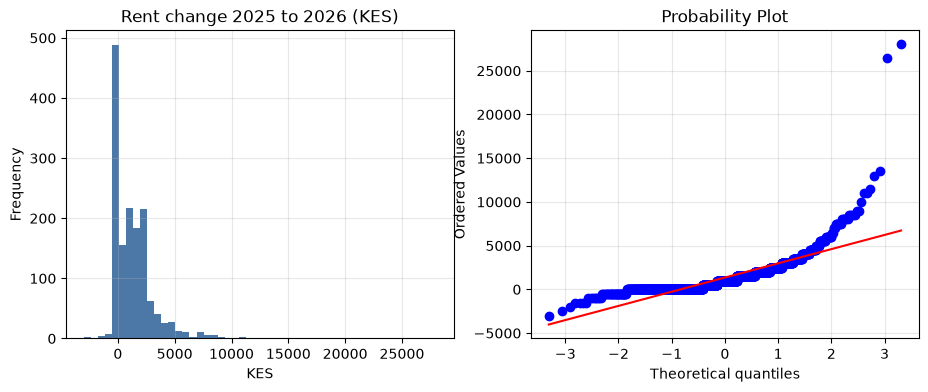

In [37]:
print("share with no change:", round((d == 0).mean(), 3), "| decreases:", (d < 0).sum(), "| skew:", round(d.skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
d.plot.hist(bins=50, ax=ax[0], color="#4c78a8"); ax[0].set(title="Rent change 2025 to 2026 (KES)", xlabel="KES")
st.probplot(d, plot=ax[1]); plt.savefig("D9_differences"); plt.show()

**Conclusion.** About 31% of units show no change, 49 units fell, and the differences are right-skewed with a spike at zero, so they are **not normal**. The paired t-test is still reasonable because it is a test about a *mean* and with n = 1,486 the CLT makes the sampling distribution of the mean difference approximately normal; the p-value is also nowhere near borderline. 

## One-way ANOVA

### D10. 2-bedroom rent across the four counties


          count      mean    median
county                             
Kajiado      31 30,251.61 30,000.00
Kiambu      344 30,394.48 28,000.00
Machakos     21 40,761.90 45,000.00
Nairobi     301 41,664.45 30,000.00
Levene: LeveneResult(statistic=np.float64(10.768611626092357), pvalue=np.float64(6.36018485203025e-07))
ANOVA : F_onewayResult(statistic=np.float64(10.04440020074371), pvalue=np.float64(1.7431407539840443e-06))
['Kajiado', 'Kiambu', 'Machakos', 'Nairobi']
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)   -142.864     1.000-13143.201 12857.474
 (0 - 2) -10510.292     0.511-30103.712  9083.128
 (0 - 3) -11412.839     0.112-24489.715  1664.037
 (1 - 0)    142.864     1.000-12857.474 13143.201
 (1 - 2) -10367.428     0.317-25950.627  5215.771
 (1 - 3) -11269.975     0.000-16741.602 -5798.348
 (2 - 0)  10510.292     0.511 -9083.128 30103.712
 (2 - 1)  10367.428     0.317 -5215.771 25950.627
 (2 - 3)   -902.547   

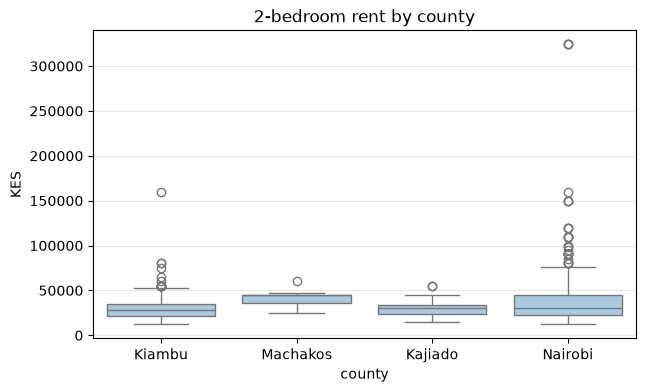

In [38]:
b2 = df[df.bedrooms == 2]
print(b2.groupby("county")["rent_kes_2026"].agg(["count", "mean", "median"]))
groups = [x["rent_kes_2026"].values for _, x in b2.groupby("county")]
names = [k for k, _ in b2.groupby("county")]
print("Levene:", st.levene(*groups)); print("ANOVA :", st.f_oneway(*groups))
print(names); print(st.tukey_hsd(*groups))
sns.boxplot(data=b2, x="county", y="rent_kes_2026", color="#a0cbe8"); plt.title("2-bedroom rent by county"); plt.ylabel("KES"); plt.savefig("D10_county_boxplot"); plt.show()

**Conclusion.** F about 10.0, p < 0.001: **reject H₀**, so 2-bedroom rents are not the same in every county. Tukey (order: Kajiado=0, Kiambu=1, Machakos=2, Nairobi=3) shows only **Kiambu vs Nairobi** differs significantly: Nairobi is about KES 11,270 more expensive. Machakos looks high too, but it has only 21 listings, so the difference is not statistically established. Levene is significant (unequal variances), so E5 repeats this with Kruskal–Wallis.

### D11. Rent by `listed_by`
**H₀:** equal mean rent for Agency, Landlord direct and Property manager.

In [39]:
G = [x["rent_kes_2026"].values for _, x in df.groupby("listed_by")]
print(df.groupby("listed_by")["rent_kes_2026"].agg(["count", "mean"])); print(st.f_oneway(*G))

                  count      mean
listed_by                        
Agency              694 34,463.69
Landlord direct     434 32,767.05
Property manager    358 33,570.67
F_onewayResult(statistic=np.float64(0.395205407771181), pvalue=np.float64(0.6736125892716722))


**Conclusion.** F about 0.40, p about 0.67: **fail to reject**. We found no evidence that rent depends on who lists the unit (as designed, since `listed_by` is random). **A non-significant result does not prove the means are equal**; it only means this data cannot detect a difference. Absence of evidence is not evidence of absence.

### D12. Rent by `market_segment`: and what if variances are unequal?

In [40]:
G = [x["rent_kes_2026"].values for _, x in df.groupby("market_segment")]
print(df.groupby("market_segment")["rent_kes_2026"].agg(["count", "mean", "median", "std"]))
print("Levene :", st.levene(*G)); print("ANOVA  :", st.f_oneway(*G))
w = anova_oneway(df["rent_kes_2026"], df["market_segment"], use_var="unequal", welch_correction=True)
print("Welch ANOVA:", w.statistic, w.pvalue); print("Kruskal:", st.kruskal(*G))

                  count       mean     median        std
market_segment                                          
Affordable          400  21,131.25  20,000.00  10,205.51
Family Friendly     646  40,629.26  32,000.00  25,494.66
Luxury               16 198,125.00 137,500.00 136,315.26
Mid-Range           194  42,365.98  35,000.00  25,060.39
Student Friendly    230  17,691.30  16,000.00   7,035.19
Levene : LeveneResult(statistic=np.float64(118.41693377268557), pvalue=np.float64(1.0300184963673786e-87))
ANOVA  : F_onewayResult(statistic=np.float64(254.8618715535985), pvalue=np.float64(1.1096707432792607e-166))
Welch ANOVA: 144.46254119231608 3.734830719375376e-42
Kruskal: KruskalResult(statistic=np.float64(620.6216022172795), pvalue=np.float64(5.332435273622091e-133))


**Conclusion.** Segment means range from about KES 17,700 (Student Friendly) to about 198,000 (Luxury). Classic ANOVA gives F about 255 with an astronomically small p, but Levene shows the variances are wildly unequal (Luxury SD about 136,000 vs Student Friendly about 7,000). **When variances are this unequal, do not rely on classic ANOVA.** Use **Welch's ANOVA** (adjusts for unequal variances) or **Kruskal–Wallis** (rank-based). All agree: rent differs strongly by market segment.

## Correlation

### D13. Distance to CBD vs rent (Pearson)
**H₀:** ρ = 0 (no linear relationship). **H₁:** ρ ≠ 0.

PearsonRResult(statistic=np.float64(-0.380768457296924), pvalue=np.float64(1.81316228978192e-52))


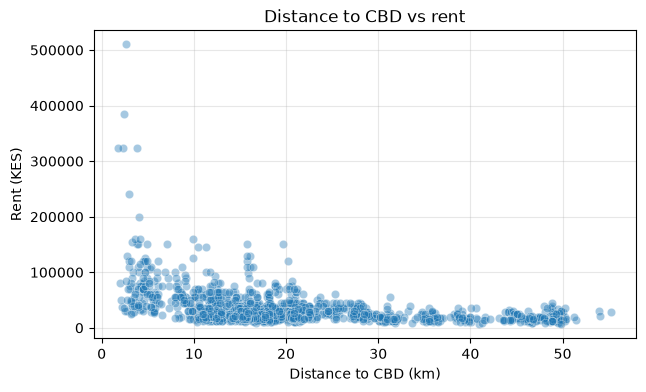

In [42]:
print(st.pearsonr(df.distance_to_cbd_km, rent))
sns.scatterplot(data=df, x="distance_to_cbd_km", y="rent_kes_2026", alpha=.4); plt.title("Distance to CBD vs rent"); plt.xlabel("Distance to CBD (km)"); plt.ylabel("Rent (KES)"); plt.savefig("D13_scatter"); plt.show()

**Conclusion.** r is about −0.38, p < 0.001. **Sign:** negative, so further from the CBD, rent tends to be lower. **Strength:** moderate (r² is about 0.145, so distance accounts for roughly 14% of the variation in rent). **Causation:** no. Distance is tangled up with other things (type of neighbourhood, housing stock, bedrooms), and correlation alone cannot say that distance *causes* cheaper rent.

# Part E — Non-parametric tests


### E1. Utawala 1-bedroom vs 18,000: Wilcoxon signed-rank
**H₀:** the median rent is 18,000 (distribution symmetric around it). **H₁:** it is not.

In [43]:
print(st.wilcoxon(u - 18000)); print('median:', u.median())

WilcoxonResult(statistic=np.float64(374.5), pvalue=np.float64(0.2303321382984178))
median: 20000.0


**Conclusion.** p about 0.23, so we fail to reject, **agreeing with the t-test (p about 0.17)**. No evidence that the agent's claim is wrong.

### E2. Parking vs no parking (2-bed): Mann–Whitney U
**H₀:** the two rent distributions are the same (a random parking unit is equally likely to cost more or less than a random non-parking unit). **H₁:** one group tends to have higher rents. *Mann–Whitney compares the overall ranks (which group tends to be larger), not means.* If the two distributions have a similar shape it can be read as a difference in medians.

In [44]:
print(st.mannwhitneyu(pk, npk, alternative='two-sided')); print('medians:', pk.median(), npk.median())

MannwhitneyuResult(statistic=np.float64(86052.5), pvalue=np.float64(6.352313865953813e-32))
medians: 35000.0 24000.0


**Conclusion.** p < 0.001: **reject H₀**. Parking units tend to rent for more (median 35,000 vs 24,000). Same conclusion as Welch's t-test.

### E3. Gym vs satisfaction: Mann–Whitney U
Satisfaction is left-skewed and capped at 10, so a rank test is the safer choice. **H₀:** satisfaction distributions are the same with and without a gym. **H₁:** they differ.

In [45]:
gy = df[df.gym == "Yes"]["tenant_satisfaction_10"]; ng = df[df.gym == "No"]["tenant_satisfaction_10"]
print("n:", len(gy), len(ng), "| medians:", gy.median(), ng.median(), "| means:", round(gy.mean(),2), round(ng.mean(),2))
print(st.mannwhitneyu(gy, ng))

n: 204 1282 | medians: 8.2 7.9 | means: 7.86 7.65
MannwhitneyuResult(statistic=np.float64(145663.5), pvalue=np.float64(0.00884483948029601))


**Conclusion.** p about 0.009: **reject H₀**. Tenants in buildings with a gym report slightly higher satisfaction (median 8.2 vs 7.9). The difference is **small** (about 0.3 of a point) and is significant mainly because of the sample size.

### E4. Paired Wilcoxon: 2025 vs 2026
**H₀:** the median change is zero. **H₁:** it is not.

In [46]:
print(st.wilcoxon(df.rent_kes_2026, df.rent_kes_2025)); print('zero differences:', (d==0).sum(), 'of', len(d))

WilcoxonResult(statistic=np.float64(9834.0), pvalue=np.float64(3.3278950273425385e-159))
zero differences: 454 of 1486


**Conclusion.** p < 0.001, so rents rose. By default the test **drops the units with zero change** (454 of 1,486) because a difference of zero has no sign to rank; it uses only the units whose rent actually changed.

### E5. 2-bedroom rent by county: Kruskal–Wallis
**H₀:** the rent distributions are the same in all four counties. **H₁:** at least one county tends to differ.

In [47]:
print(st.kruskal(*groups))
print(b2.groupby("county")["rent_kes_2026"].median())

KruskalResult(statistic=np.float64(24.34774458497935), pvalue=np.float64(2.1133576133513455e-05))
county
Kajiado    30,000.00
Kiambu     28,000.00
Machakos   45,000.00
Nairobi    30,000.00
Name: rent_kes_2026, dtype: float64


**Conclusion.** H about 24.3, p < 0.001, agreeing with the ANOVA. Medians: Machakos (45,000) is highest, then Kajiado (30,000), Nairobi (30,000) and Kiambu (28,000). **Machakos** stands apart at the centre of its distribution, while Nairobi's higher *mean* (about 41,700 vs median 30,000) is driven by its expensive tail, and Kiambu is the cheapest. Kruskal–Wallis only says 'at least one differs'; a post-hoc test (e.g. Dunn) would say which pairs, and the small Machakos (21) and Kajiado (31) groups limit what we can conclude.

### E6. Spearman vs Pearson

In [48]:
print("Pearson :", st.pearsonr(df.distance_to_cbd_km, rent)[0]); print("Spearman:", st.spearmanr(df.distance_to_cbd_km, rent))

Pearson : -0.380768457296924
Spearman: SignificanceResult(statistic=np.float64(-0.46558307390774706), pvalue=np.float64(8.202796885199105e-81))


**Conclusion.** Spearman ρ is about −0.47 vs Pearson r about −0.38. Spearman is stronger because it detects any consistently decreasing (monotonic) relationship using ranks. The distance–rent relationship curves rather than following a straight line, and Pearson is also dragged down by the extreme-rent outliers; ranks ignore how extreme those values are.

### E7. Chi-square: furnished vs market segment
**H₀:** furnished status is independent of market segment. **H₁:** they are related.

In [49]:
ct = pd.crosstab(df.furnished, df.market_segment); chi = st.chi2_contingency(ct)
print(ct); print("chi2 =", round(chi.statistic, 1), "df =", chi.dof, "p =", chi.pvalue)
exp = pd.DataFrame(chi.expected_freq, index=ct.index, columns=ct.columns).round(1); print("Expected counts:"); print(exp)
print("Cells with expected < 5:", (exp < 5).sum().sum())

market_segment  Affordable  Family Friendly  Luxury  Mid-Range  \
furnished                                                        
No                     390              542       9        170   
Yes                     10              104       7         24   

market_segment  Student Friendly  
furnished                         
No                           223  
Yes                            7  
chi2 = 83.7 df = 4 p = 2.800600415020062e-17
Expected counts:
market_segment  Affordable  Family Friendly  Luxury  Mid-Range  \
furnished                                                        
No                  359.10           579.90   14.40     174.20   
Yes                  40.90            66.10    1.60      19.80   

market_segment  Student Friendly  
furnished                         
No                        206.50  
Yes                        23.50  
Cells with expected < 5: 1


**Conclusion.** χ² about 83.7, df = 4, p < 0.001, so furnished status **is related** to market segment: only about 2% of Affordable and 3% of Student Friendly units are furnished, against about 16% of Family Friendly, 12% of Mid-Range and 44% of Luxury units.

**Expected counts:** one cell is below 5, the Luxury and furnished cell (expected about 1.6), because the Luxury segment has only 16 units. The chi-square approximation is unreliable for that cell. What I would do: **merge Luxury with Mid-Range** (an 'upper' segment) and re-run, or use a simulation-based / exact test. With only 1 of 10 cells affected and an enormous χ², the conclusion is very unlikely to change.

### E8. Chi-square: parking vs county
**H₀:** parking is independent of county. **H₁:** they are related.

In [50]:
ct2 = pd.crosstab(df.parking, df.county); c2 = st.chi2_contingency(ct2)
print(ct2); print("chi2 =", round(c2.statistic, 2), "df =", c2.dof, "p =", round(c2.pvalue, 4), "| min expected:", round(c2.expected_freq.min(), 1))
print(pd.crosstab(df.parking, df.county, normalize="columns").round(3))
print("Cramer's V:", round(np.sqrt(c2.statistic / len(df)), 3))

county   Kajiado  Kiambu  Machakos  Nairobi
parking                                    
No            28     331        17      232
Yes           36     412        34      396
chi2 = 9.58 df = 3 p = 0.0225 | min expected: 20.9
county   Kajiado  Kiambu  Machakos  Nairobi
parking                                    
No          0.44    0.45      0.33     0.37
Yes         0.56    0.56      0.67     0.63
Cramer's V: 0.08


**Conclusion.** χ² about 9.58, df = 3, p about 0.022: we reject independence at 5%. Parking is more common in Nairobi (63% of listings) and Machakos (67%) than in Kiambu (55%) and Kajiado (56%). The association is **weak** (Cramér's V about 0.08), and all expected counts are at least 5, so the test is valid.

### E9. Chi-square goodness of fit: listings evenly spread over weekdays?
**H₀:** listings are equally likely on each of the 7 days. **H₁:** they are not.

listing_weekday
Mon    256
Tue    334
Wed    243
Thu    304
Fri    222
Sat    110
Sun     17
Name: count, dtype: int64
Power_divergenceResult(statistic=np.float64(352.23014804845224), pvalue=np.float64(5.124955157501235e-73))


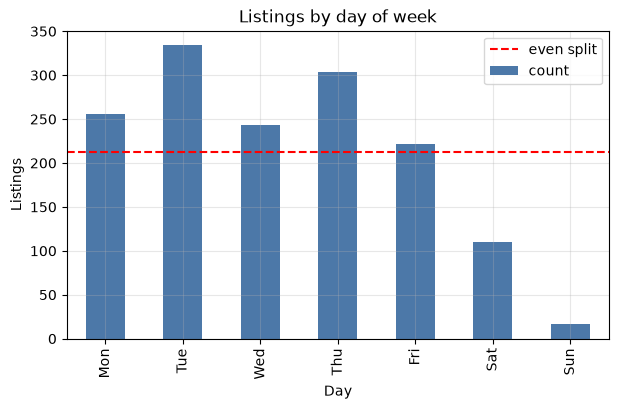

In [51]:
order = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
w = df.listing_weekday.value_counts().reindex(order); print(w); print(st.chisquare(w))
w.plot.bar(color="#4c78a8"); plt.axhline(len(df)/7, color="red", ls="--", label="even split"); plt.title("Listings by day of week"); plt.xlabel("Day"); plt.ylabel("Listings"); plt.legend(); plt.savefig("E9_weekday"); plt.show()

**Conclusion.** χ² about 352, p < 0.001: listings are **not** spread evenly. Tuesday (334) is the busiest day and Sunday (17) the quietest. A real-world explanation: agents and property managers upload listings during working days and rest on weekends.

### E10. What I would report to a client
- **D1 (Utawala 1-bed vs 18,000):** I would report the **Wilcoxon result alongside the median**, since n = 51 and the data are mildly skewed; both tests agree there is no evidence against KES 18,000.
- **D4 (parking premium, 2-bed):** I would report **Welch's t-test with the mean difference (about KES 16,000)** and confirm it with Mann–Whitney, because variances are very unequal and rents are skewed; both give the same conclusion.
- **D7 (2025 to 2026 change):** I would report the **paired t-test (about KES 1,357, roughly a 4% rise)**, since n is large and the question is about the average change, and mention the Wilcoxon result as confirmation because the differences are not normal.
- **D10 (2-bed rent by county):** I would report **Kruskal–Wallis with the county medians**, because variances are unequal and Nairobi's mean is inflated by a few expensive units.

# Extension tasks

## 1. Market brief: Ruaka vs Utawala vs Syokimau
*Descriptive statistics and one test, for a first-time renter.*

               listings  median_rent        q1        q3  mean_rent  \
neighbourhood                                                         
Ruaka                64    33,000.00 23,000.00 45,000.00  35,796.90   
Syokimau             42    45,000.00 36,000.00 63,750.00  49,821.40   
Utawala             104    22,500.00 18,000.00 30,000.00  24,918.30   

               km_to_cbd  commute_min  pct_parking  
neighbourhood                                       
Ruaka              12.30        47.00        65.60  
Syokimau           20.40        46.90        71.40  
Utawala            21.20        50.20        59.60  
bedrooms              0         1         2         3
neighbourhood                                        
Ruaka         13,000.00 33,000.00 43,000.00 83,000.00
Syokimau            NaN 22,000.00 45,000.00 70,000.00
Utawala             NaN 20,000.00 27,500.00 40,000.00


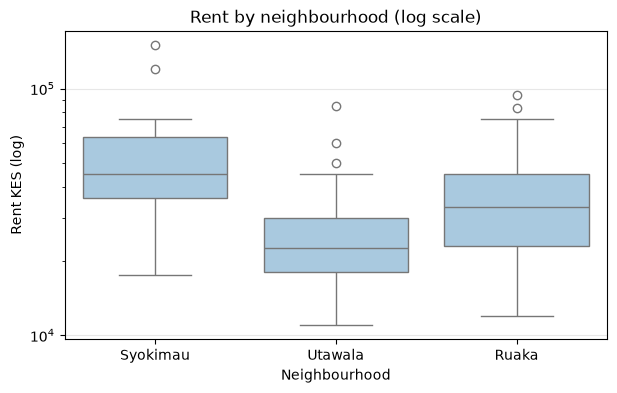

KruskalResult(statistic=np.float64(57.13283601724863), pvalue=np.float64(3.9243008198574916e-13))


In [52]:
three = df[df.neighbourhood.isin(["Ruaka", "Utawala", "Syokimau"])]
brief = three.groupby("neighbourhood").agg(
    listings=("rent_kes_2026", "size"), median_rent=("rent_kes_2026", "median"),
    q1=("rent_kes_2026", lambda x: x.quantile(.25)), q3=("rent_kes_2026", lambda x: x.quantile(.75)),
    mean_rent=("rent_kes_2026", "mean"), km_to_cbd=("distance_to_cbd_km", "mean"),
    commute_min=("peak_commute_min", "mean"), pct_parking=("parking", lambda x: (x=="Yes").mean()*100))
print(brief.round(1))
print(three.groupby(["neighbourhood", "bedrooms"])["rent_kes_2026"].median().unstack().loc[:, [0,1,2,3]])
sns.boxplot(data=three, x="neighbourhood", y="rent_kes_2026", color="#a0cbe8"); plt.yscale("log"); plt.title("Rent by neighbourhood (log scale)"); plt.xlabel("Neighbourhood"); plt.ylabel("Rent KES (log)"); plt.savefig("X1_three_neighbourhoods"); plt.show()
print(st.kruskal(*[x["rent_kes_2026"] for _, x in three.groupby("neighbourhood")]))

**Brief for a first-time renter.**
- **Utawala** is the **cheapest**: median about KES 22,500 (middle half 18,000 to 30,000) and the most listings (104), so the most choice. It is also the farthest from the CBD (about 21 km) with the longest average peak commute (about 50 min).
- **Ruaka** is mid-priced (median about 33,000) and **closest to the CBD (about 12 km)**, with a commute of about 47 min.
- **Syokimau** is the **most expensive** (median about 45,000; mean about 49,800 because high-end homes pull it up), about 20 km from the CBD, commute about 47 min.
- **Compare like with like:** the neighbourhoods also differ in unit mix. By bedrooms, the median 1-bedroom is about 20,000 in Utawala, 22,000 in Syokimau and 33,000 in Ruaka; for 2-bedrooms about 27,500, 45,000 and 43,000.
- **One test (Kruskal–Wallis; H₀: the rent distributions are the same in all three):** H about 57, p < 0.001, so the rent differences are real, not chance. I used a rank test because rents are skewed.
- **Caution:** commute and parking figures are simulated, so they should not be relied on as market facts.
- **Advice:** on a tight budget, Utawala. Want a short trip to the CBD and a mid-range price, Ruaka. Syokimau is the premium option for larger units, though its 1-bedrooms are comparatively affordable.

## 2. Floor level and rent in buildings with six or more floors
*I define 'six or more floors' as buildings whose highest recorded `floor_level` is at least 5 (levels 0 to 5 make six floors). This only uses floors visible in the listings, so it is an approximation.*

units: 316 | buildings: 140
SignificanceResult(statistic=np.float64(0.38017537985384636), pvalue=np.float64(2.637818749706672e-12))
             count    median
floor_level                 
0-1             27 24,000.00
2-3             56 20,750.00
4-5            113 26,000.00
6+             120 45,000.00


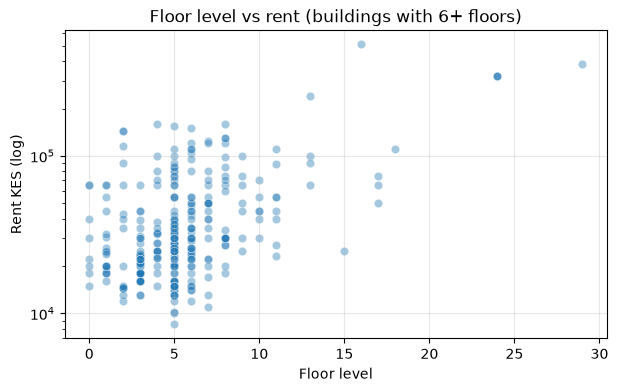

In [53]:
df["max_floor"] = df.groupby("building_id")["floor_level"].transform("max")
tall = df[df.max_floor >= 5]
print("units:", len(tall), "| buildings:", tall.building_id.nunique())
print(st.spearmanr(tall.floor_level, tall.rent_kes_2026))
print(tall.groupby(pd.cut(tall.floor_level, [-1, 1, 3, 5, 100], labels=["0-1", "2-3", "4-5", "6+"]), observed=True)["rent_kes_2026"].agg(["count", "median"]))
sns.scatterplot(data=tall, x="floor_level", y="rent_kes_2026", alpha=.4); plt.yscale("log"); plt.title("Floor level vs rent (buildings with 6+ floors)"); plt.xlabel("Floor level"); plt.ylabel("Rent KES (log)"); plt.savefig("X2_floor_rent"); plt.show()

**Interpretation.** There is a positive rank correlation (ρ about 0.38, p < 0.001): higher floors tend to have higher rent. The medians by floor band are 24,000 (floors 0–1, n=27), 20,750 (2–3), 26,000 (4–5) and 45,000 (6 and above, n=120), so the premium is not a smooth step-by-step rise: it is concentrated in the highest floors. **But** units in a tall building are not independent (see below), and tall buildings are probably in pricier areas, so floor level may partly stand in for *building type and location* rather than being a pure 'floor premium'.

## 3. Are units in the same building independent?

In [54]:
sizes = df.groupby("building_id").size()
print("buildings:", len(sizes), "| with 2+ units:", (sizes >= 2).sum(), "| units in those:", sizes[sizes >= 2].sum(), "| largest:", sizes.max())
multi = df[df.building_id.isin(sizes[sizes >= 2].index)]
Gb = [x["rent_kes_2026"].values for _, x in multi.groupby("building_id")]
print("Rent differs by building (Kruskal):", st.kruskal(*Gb))
# robustness: re-run the floor-level test with ONE random unit per building
one = tall.groupby("building_id").sample(1, random_state=0)
print("one unit per building -> n =", len(one), st.spearmanr(one.floor_level, one.rent_kes_2026))

buildings: 944 | with 2+ units: 307 | units in those: 849 | largest: 16
Rent differs by building (Kruskal): KruskalResult(statistic=np.float64(779.549231635643), pvalue=np.float64(4.192555506725557e-43))
one unit per building -> n = 140 SignificanceResult(statistic=np.float64(0.3298625717614935), pvalue=np.float64(6.892159535016518e-05))


**Discussion.** Units in the same building share a landlord, location, amenities, age and management, so their rents are **more alike than two random units**. They are **not independent observations**: the data are *clustered*. Every test in this notebook assumes independent rows. When rows are clustered:
- the *effective* sample size is smaller than 1,486 (a building with 10 units gives much less than 10 units' worth of independent information);
- standard errors come out too small, so p-values are too small and confidence intervals too narrow, and we become **too ready to declare significance**.

In this dataset there are 944 buildings for 1,486 listings. Most buildings have one unit, but 307 buildings hold 849 units (57% of all listings) and the largest has 16, and a Kruskal–Wallis test across those buildings is overwhelmingly significant (rents differ strongly from building to building), so clustering is a real issue. As a simple check, re-running the floor-level test with one random unit per building keeps the result (ρ about 0.33, p < 0.001, n = 140 instead of 316), so that finding is reasonably robust, though the confidence is lower; proper remedies are **cluster-robust standard errors or mixed-effects (multilevel) models** with building as a grouping factor, which go beyond this guide.